# Runnable Part2

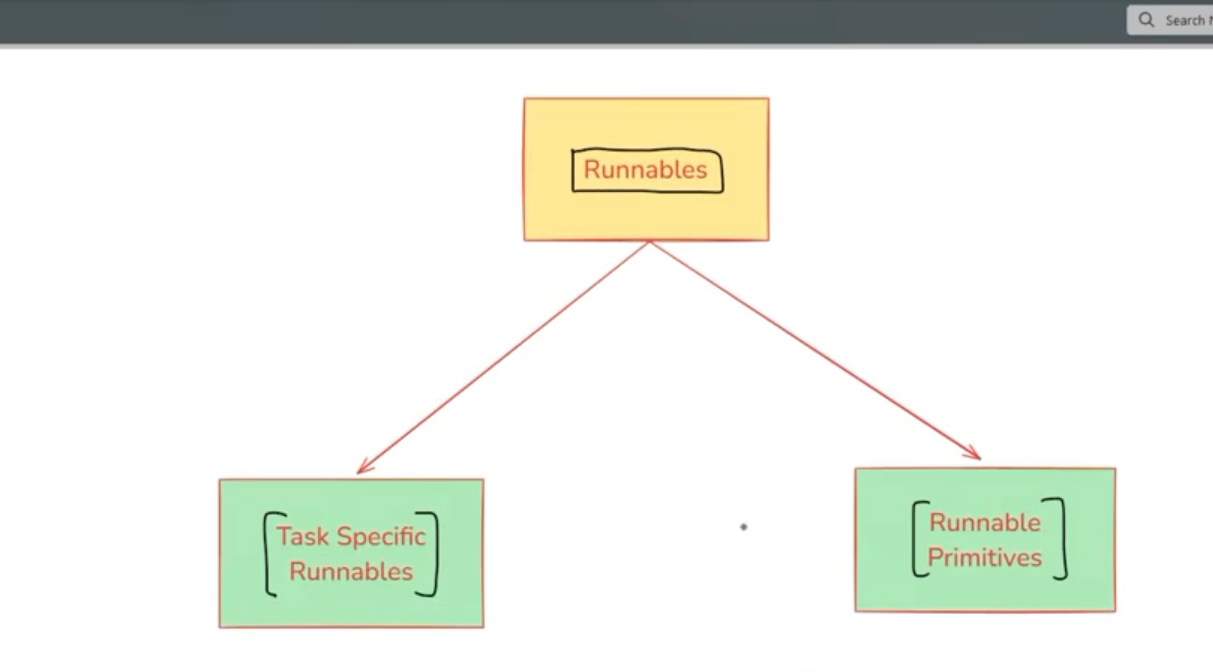

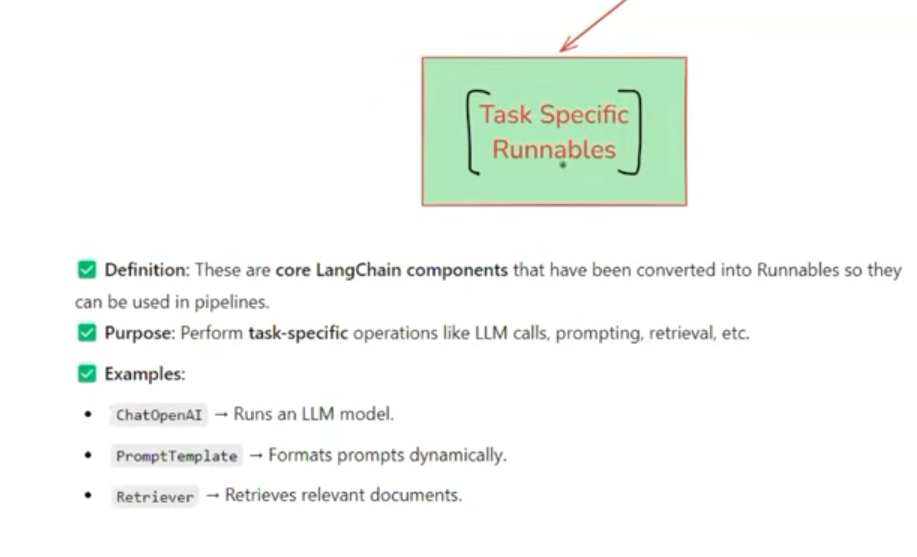

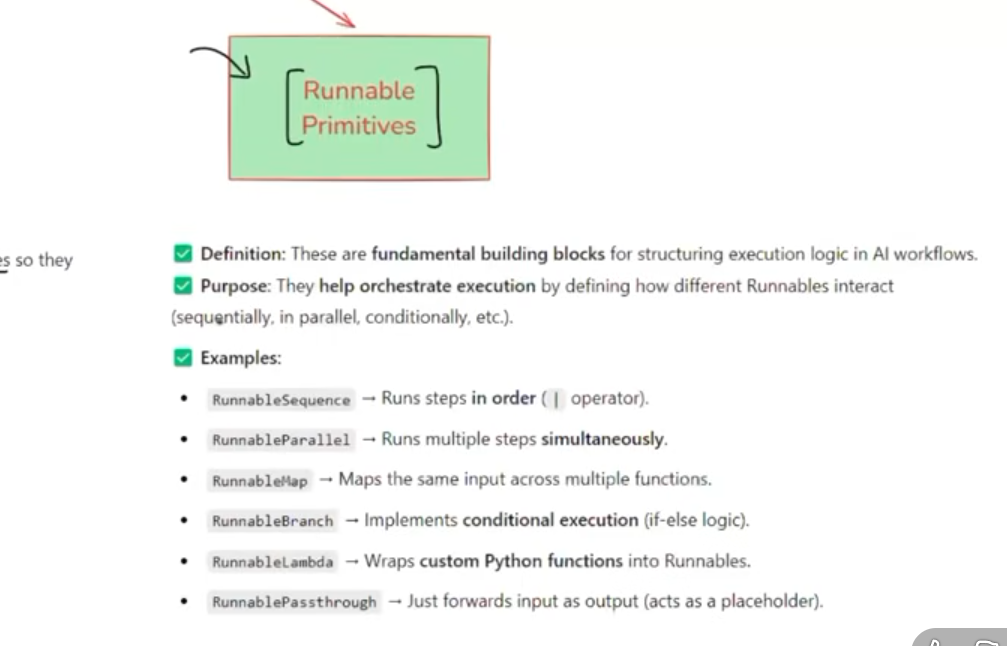

task specifc runnables hunde hai jinda da apna koi kaam hunda hai mtlb core components of langchain jihna nu runnable bnaya janda hai pipeline bnane lyi
eg promptTemplate,retriever etc

RUnnable primitives saanu task specific runnable connect krne vich help krde hai te dsde hai task specific runnable kida connect hai

## Runnable Sequence

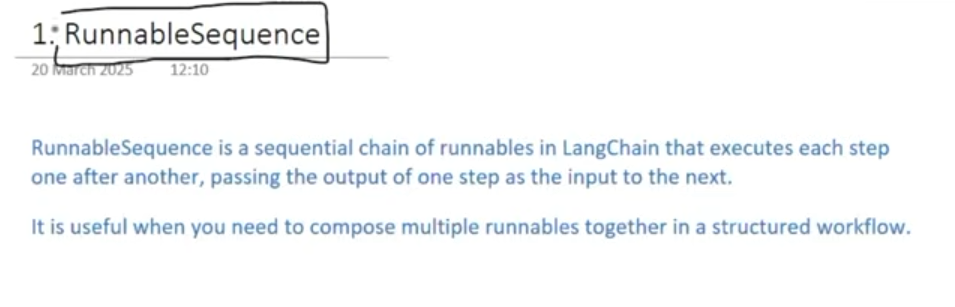

In [8]:
from langchain_ollama import ChatOllama
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableSequence
model=ChatOllama(
    model='llama3.2:1b',
    temperature=0.7
)
prompt1=PromptTemplate(
    template='Write a joke about {topic}',
    input_variables=['topic']
)
prompt2=PromptTemplate(
    template='Explain the given joke \n {joke}',
    input_variables=['joke']
)
parser=StrOutputParser()
chain=RunnableSequence(prompt1, model, parser, prompt2, model, parser)
result=chain.invoke({'topic':'study'})
print(result)


This joke is a play on words. The student brings a ladder to school, but the phrase "reach their full potential" has a double meaning here.

In one sense, a ladder is a physical object that allows someone to reach high places, which is exactly what the student wants to do in school. They want to reach their academic goals and have a better understanding of the material.

However, the phrase "reach their full potential" also has a second meaning. It can refer to personal growth and development, where someone strives to achieve their full potential as a person, which is often associated with personal achievement, self-improvement, and success.

In this joke, the student brings the ladder to school as a way of symbolically "reaching" their full potential, both literally and figuratively. It's a clever play on words that uses the concept of a ladder to make a pun on the phrase "reach one's full potential."


## Runnable Parellel

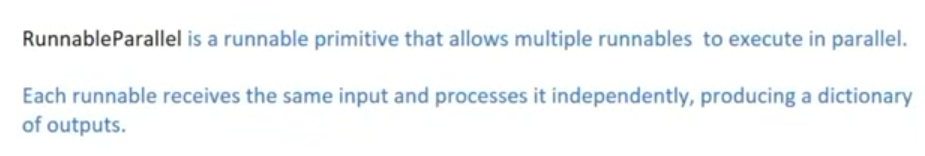

In [15]:
from langchain_ollama import ChatOllama
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableSequence,RunnableParallel
model2=ChatOllama(
    model='llama3.2:1b',
    temperature=0.7
)
model1=ChatOllama(
    model='llama3.2:1b',
    temperature=0.3
)

prompt1=PromptTemplate(
    template='Generate a tweet on topic {topic}',
    input_variables=['topic']
)
prompt2=PromptTemplate(
    template='Generate a linkdin post for topic {topic}',
    input_variables=['topic']
)
parellel_chain=RunnableParallel({
    'tweet':RunnableSequence(prompt1,model2,parser),
    'linkdin':RunnableSequence(prompt2,model1,parser)
})

result=parellel_chain.invoke({'topic':'Ai'})
print(result['linkdin'])

Here's a potential LinkedIn post on the topic of AI:

**Title:** The Future of Work: How AI is Revolutionizing Industries and Careers

**Text:**

As we continue to navigate the rapidly changing landscape of work, it's essential to stay ahead of the curve and understand the impact of Artificial Intelligence (AI) on various industries and careers.

AI is no longer just a buzzword; it's a game-changer. From automation and robotics to natural language processing and machine learning, AI is transforming the way we work, live, and interact with each other.

But what does this mean for us? Here are a few key takeaways:

 **Increased efficiency and productivity**: AI can automate repetitive tasks, freeing up time for more strategic and creative work.
 **Improved decision-making**: AI-powered tools can analyze vast amounts of data, providing insights that can inform better decisions.
 **Enhanced customer experience**: AI-driven chatbots and virtual assistants can provide 24/7 support, improving

## Runnable passthrough

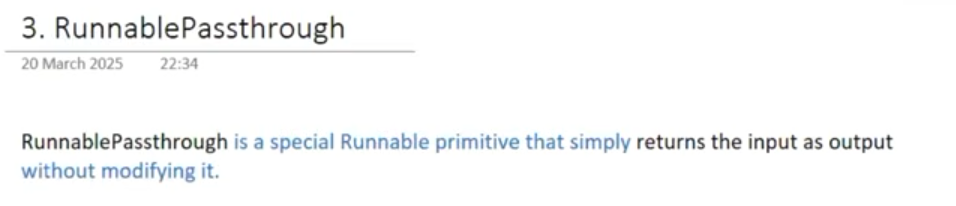

last example jo hmne kiya jisme joke maanga fir explanation of joke maanga or print bs explanantion hua tha ab hmari requirement hai ki hme dono joke or explanation print krni hai to runnablePassthrough use hoga

In [17]:
from langchain_ollama import ChatOllama
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableSequence,RunnableParallel,RunnablePassthrough
model=ChatOllama(
    model='llama3.2:1b',
    temperature=0.7
)
passthrough=RunnablePassthrough()
passthrough.invoke(2)
print(2)# runnable passthrough ka yhi kaam hai jo input aaya usse output bna do

2


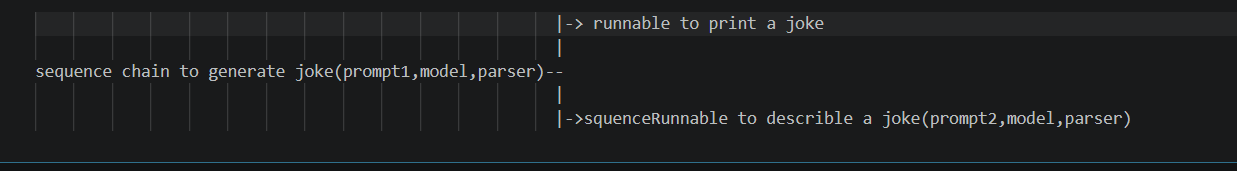

In [23]:
from langchain_ollama import ChatOllama
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableSequence
model=ChatOllama(
    model='llama3.2:1b',
    temperature=0.7
)
prompt1=PromptTemplate(
    template='Write a joke about {topic}',
    input_variables=['topic']
)
prompt2=PromptTemplate(
    template='Explain the given joke \n {joke}',
    input_variables=['joke']
)

joke_gen_chain=RunnableSequence(prompt1, model, parser)
parellel_chain=RunnableParallel({
    'joke':RunnablePassthrough(),
    'Explanation':RunnableSequence(prompt2, model, parser)
})

final_chain=RunnableSequence(joke_gen_chain,parellel_chain)
result=final_chain.invoke({'topic':'cricket'})
print(result['Explanation'])
print('joke',result['joke'])


A classic play on words. The joke relies on the pun between "back" (a reference to the cricket's physical back) and "back" (a reference to the doctor's office).

In the joke, the cricket says it had a "bad back" because, in cricket, a "back" refers to the back of the bat, which is used to hit the ball. So, the cricket is literally saying it has a bad bat, implying that it's not hitting the ball well or effectively. The humor comes from the unexpected twist on the word "back" and the clever connection between the cricket's physical situation and its actions.
joke Why did the cricket go to the doctor?

Because it had a bad back.


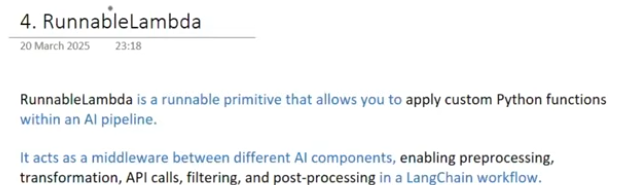

runnable lambda kisi vi python functions nu runnable vich convert kr skda hai joki pipe lines vich use ho skde hai

example naal smjh
1. data acquire kita jo ki reviews hai
2. llm kol bhjya data
3. sentiment analyses

ab hmne dekha ki jo hmara data vo clean nhi hai usme stop words hai ,punctuations hai,emojis hai to hmne ek function bnaya preprocessing ka jisme basic preprocessing krenge jaise emojis htana, punctuation htaja ,lemmitization etc ab yeh ek python function hai hm RunnableLOambda use krke is pyhton function ko runnable bna skdte fir jo yeh clean krke output dega usse directly llm sarh pipeline mai use kr skte hai

In [26]:
from langchain_ollama import ChatOllama
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableSequence,RunnableLambda
model=ChatOllama(
    model='llama3.2:1b',
    temperature=0.7
)
def word_counter(text):
    return len(text.split())

runnable=RunnableLambda(word_counter)
result=runnable.invoke('this is a hello word')
print(result)


5


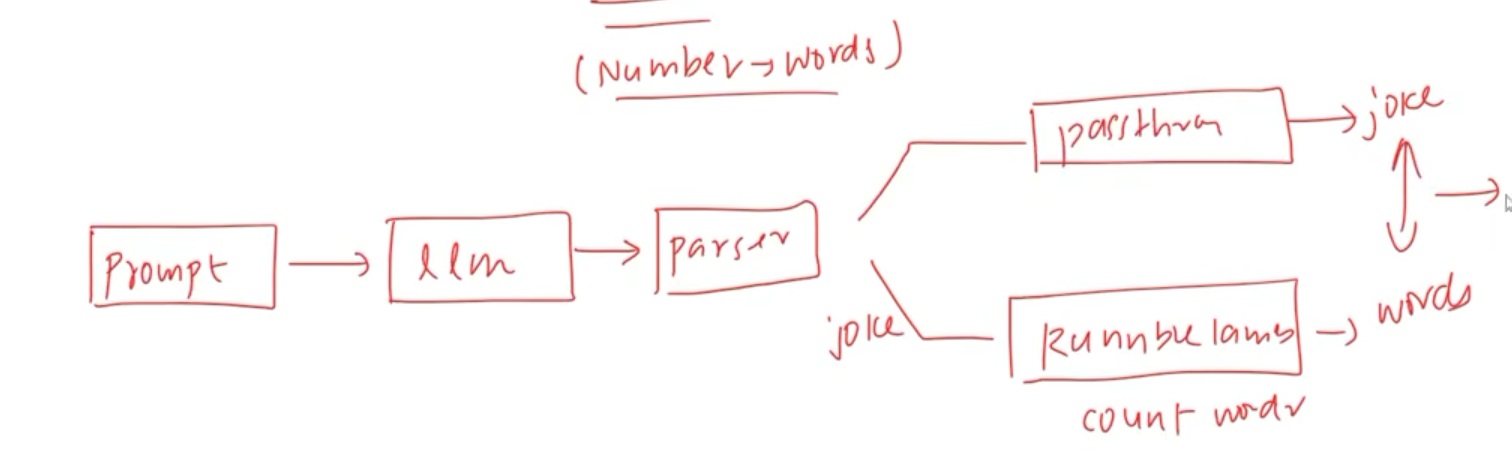

In [29]:
from langchain_ollama import ChatOllama
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableSequence,RunnableLambda
model=ChatOllama(
    model='llama3.2:1b',
    temperature=0.7
)
prompt1=PromptTemplate(
    template='Write a joke about {topic}',
    input_variables=['topic']
)

def word_counter(text):
    return len(text.split())

joke_gen_chain=RunnableSequence(prompt1, model, parser)
parellel_chain=RunnableParallel({
    'joke':RunnablePassthrough(),
    'Word_count':RunnableLambda(word_counter)
})

final_chain=RunnableSequence(joke_gen_chain,parellel_chain)
result=final_chain.invoke({'topic':'cricket'})
print(result)


{'joke': 'Why did the cricket go to the doctor?\n\nBecause it was feeling a little "off-base."', 'Word_count': 15}


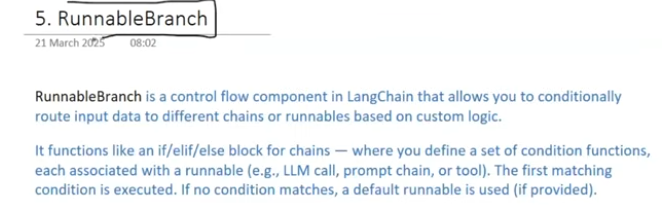

question hai ek topic diya uspe report generate krwai agr to report 500 words se km hai to direct print agr 500 words se jyada hai to dobara llm pass bhj lr summarize krao

In [34]:
from langchain_ollama import ChatOllama
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableSequence,RunnableLambda,RunnableBranch,RunnablePassthrough,RunnableParallel
model=ChatOllama(
    model='llama3.2:1b',
    temperature=0.7
)
prompt1=PromptTemplate(
    template='Generate a report on topic {topic}',
    input_variables=['topic']
)
prompt2=PromptTemplate(
    template='Summarize the given topic {text}',
    input_varuables=['text']
)
parser=StrOutputParser()
report_gen_chain=RunnableSequence(prompt1, model, parser)
branch_chain=RunnableBranch(
    (lambda x : len(x.split())>500,RunnableSequence(prompt2, model , parser)),
    RunnablePassthrough() 
)
final_chain=RunnableSequence(report_gen_chain,branch_chain)
result=final_chain.invoke({'topic','watch'})
print(result)

The report "Watch" and "Topic" explores the concept of watching as a complex and multifaceted phenomenon, encompassing various aspects of our behavior, attitudes, and preferences. It delves into the different types of watching, its impact on our lives, and the various aspects of this behavior. The report provides a comprehensive overview of the topic, highlighting the benefits and drawbacks of watching and offering insights into its significance in modern life.


## LCEL (langchain expression language)

runnable sequence bht use hunda hai ta krke sytax simple krta
r1 | r2 | r3 (r1,r2,r3 runnables hai)